# Zero-shot evaluation of Meta's pretrained I-JEPA predictor (plan items 7a and 6)

**The idea.** Our 4-layer predictor is trained from scratch on 188 to 352 images and sees *latents of the full image*: every visible token has already attended to the whole image, defect included, through all 40 encoder layers (the "context leakage" of item 6). Meta's checkpoint also contains the **context encoder** and a **16-layer predictor** trained on ImageNet-22k for exactly this task: encode only the *visible* patches, then predict the target-encoder latents of the masked block.

So this notebook runs, for every 4x4 coarse window of an image,

1. Meta's context encoder on the 180 tokens **outside** the window (input masking, no leakage),
2. Meta's pretrained predictor for the window's tokens,
3. `1 - cos` against the **cached target-encoder latents** (the same latents our predictor is scored against).

Nothing is trained or fine-tuned. The target latents are not recomputed; the images are passed through the context encoder, which is unavoidable because input masking needs pixels.

**What is compared (declared before any result)**

| Row | Scores | Coarse windows |
| --- | --- | --- |
| `trained` | our baseline predictor, `1 - cos` | 4x4, coarse pass only |
| `pretrained` | Meta's context encoder + predictor, `1 - cos` | 4x4, coarse pass only |
| `trained + z` / `pretrained + z` | the same, with the per-position z-score selected in notebook 06 (statistics from all nominal validation images) | 4x4 |

* Both models are compared in **coarse-only** mode because the pretrained path costs one context-encoder pass per window, so the dense fine pass (196 passes per image) is out of reach, and in the baseline the fine pass fires on at most 1.2% of test images (`masks/image` 16.0 to 16.2), so coarse-only is the same method for practical purposes. The `trained` row is checked against the saved baseline.
* The headline comparison uses the settings chosen in notebook 06 (`pos_zscore`, `k = 3`): `pretrained + z` against `trained + z`. The raw rows and the plain max score are also reported.
* Paired-bootstrap 95% intervals on image AUROC, as in notebooks 04 to 07. An interval containing 0 is `inconclusive`.

The pretrained model is loaded memory-mapped in fp32 (about 4 GB on the GPU, under 2 GB of host RAM). If the results are poor, that is a finding about zero-shot transfer from ImageNet-22k, not about the pipeline: the checks below confirm the pipeline first.

## 1. Configuration, splits, caches, models

In [1]:
import json
import os
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import yaml
from PIL import Image

try:
    display
except NameError:
    display = print

candidates = (Path.cwd(), *Path.cwd().parents)
PROJECT_ROOT = next((p for p in candidates if (p / 'configs').is_dir() and (p / 'src').is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Run this notebook from the repository or its notebooks directory.')
sys.path.insert(0, str(PROJECT_ROOT / 'src'))

CATEGORIES = ('bottle', 'capsule', 'hazelnut')
ENCODER_CHECKPOINT = PROJECT_ROOT / 'checkpoints' / 'IN22K-vit.g.16-600e.pth.tar'
OFFICIAL_IJEPA_ROOT = PROJECT_ROOT / 'external' / 'ijepa'
BASELINE_CHECKPOINTS = PROJECT_ROOT / 'checkpoints' / 'predictors'
CACHE_ROOT = PROJECT_ROOT / 'data' / 'cache' / 'latents'
TEST_CACHE_ROOT = PROJECT_ROOT / 'data' / 'cache' / 'latents_test'
PREDICTION_CACHE = PROJECT_ROOT / 'data' / 'cache' / 'pretrained_zero_shot'
SELECTION_PATH = PROJECT_ROOT / 'results' / 'improvements' / 'synthetic_val' / 'selected_settings.json'
OUTPUT_ROOT = Path(os.environ.get('ZERO_SHOT_OUTPUT', PROJECT_ROOT / 'results' / 'improvements' / 'pretrained_zero_shot'))
OVERWRITE = False
OUTPUT_FILES = ('zero_shot_metrics.csv', 'bootstrap_deltas.csv', 'nominal_diagnostics.csv', 'zero_shot_summary.json')
MASKING_CONFIG_PATH = PROJECT_ROOT / 'configs' / 'masking' / 'coarse_to_fine.yaml'
DATA_CONFIG = yaml.safe_load((PROJECT_ROOT / 'configs' / 'data' / 'mvtec.yaml').read_text(encoding='utf-8'))
VAL_FRACTION = float(DATA_CONFIG['nominal_split']['val_fraction'])
SPLIT_SEED = int(DATA_CONFIG['nominal_split']['seed'])
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
N_BOOTSTRAP, BOOTSTRAP_SEED = 1000, 0
POSITION_STD_FLOOR_FRACTION = 0.5            # declared in notebook 05

if not OVERWRITE:
    existing = [OUTPUT_ROOT / n for n in OUTPUT_FILES if (OUTPUT_ROOT / n).exists()]
    if existing:
        raise FileExistsError('Refusing to overwrite: ' + ', '.join(map(str, existing)) + ' (set OVERWRITE = True)')

selection = json.loads(SELECTION_PATH.read_text(encoding='utf-8'))
if selection['test_used_for_selection'] is not False:
    raise ValueError('The selection file says the test split influenced the choice.')
SELECTED = selection['selected_settings']
if SELECTED['family'] != 'pos_zscore':
    raise ValueError('This notebook applies the per-position z-score selected in notebook 06; the selection changed.')
K = int(SELECTED['k'])
print('settings from notebook 06:', SELECTED)

settings from notebook 06: {'family': 'pos_zscore', 'k': 3, 'lam': 1.0, 'sigma': 0.0, 'tau': 'default'}


In [2]:
from ijepa_ad.caching.cache_schema import CacheExpectations, PreprocessingSpec
from ijepa_ad.caching.latent_cache import compute_file_sha256
from ijepa_ad.data.mvtec_dataset import validate_category_splits
from ijepa_ad.data.splits import split_nominal_train_val
from ijepa_ad.data.transforms import PreprocessConfig, preprocess_image
from ijepa_ad.encoder.ijepa_pretrained_predictor import IJEPAContextPredictor
from ijepa_ad.evaluation.metrics import aupro, image_auroc, pixel_auroc
from ijepa_ad.evaluation.runner import EMBEDDING_DIM, ENCODER_NAME, NUM_TOKENS, PATCH_SIZE
from ijepa_ad.inference import MaskedLatentScorer, load_masking_settings, load_predictor_checkpoint_with_provenance
from ijepa_ad.masking.score_maps import upsample_patch_scores
from ijepa_ad.predictor.cache_dataset import load_cached_latent_dataset
from ijepa_ad.scoring import PositionNormaliser, cosine_discrepancy

ENCODER_SHA256 = compute_file_sha256(ENCODER_CHECKPOINT)
MASKING_SETTINGS = load_masking_settings(MASKING_CONFIG_PATH)
PREPROCESS = PreprocessConfig(image_size=int(DATA_CONFIG['preprocessing']['image_size']))
PREPROCESSING_SPEC = PreprocessingSpec.from_config(PREPROCESS)


def expectations(category, split, samples):
    return CacheExpectations(
        category=category, split=split, encoder_name=ENCODER_NAME, checkpoint_sha256=ENCODER_SHA256,
        patch_size=PATCH_SIZE, embedding_dim=EMBEDDING_DIM, preprocessing=PREPROCESSING_SPEC,
        sample_ids=tuple(s.image_id for s in samples), num_tokens=NUM_TOKENS,
    )


PREDICTORS, VAL, TESTSET = {}, {}, {}
for category in CATEGORIES:
    root = next(r for r in (PROJECT_ROOT / DATA_CONFIG['root'], PROJECT_ROOT / 'dataset', PROJECT_ROOT / 'dataset' / category)
                if (r / category / 'train').is_dir())
    train_ds, test_ds = validate_category_splits(root, category)
    nominal = split_nominal_train_val(
        train_ds.samples, val_fraction=VAL_FRACTION, seed=SPLIT_SEED,
        min_train=int(DATA_CONFIG['nominal_split']['min_train']), min_val=int(DATA_CONFIG['nominal_split']['min_val']),
    )
    VAL[category] = load_cached_latent_dataset(CACHE_ROOT, expectations(category, 'val', nominal.val), samples=train_ds.samples)
    TESTSET[category] = load_cached_latent_dataset(TEST_CACHE_ROOT, expectations(category, 'test', test_ds.samples), samples=test_ds.samples)
    PREDICTORS[category], _ = load_predictor_checkpoint_with_provenance(
        BASELINE_CHECKPOINTS / f'{category}_cosine.pt', category=category, encoder_sha256=ENCODER_SHA256, device=DEVICE)
    print(f'{category}: val={len(VAL[category])}, test={len(TESTSET[category])}')

started = time.perf_counter()
PRETRAINED = IJEPAContextPredictor(ENCODER_CHECKPOINT, official_repo_path=OFFICIAL_IJEPA_ROOT, device=DEVICE)
print(f'pretrained context encoder + predictor loaded in {time.perf_counter() - started:.0f}s '
      f'({sum(p.numel() for p in PRETRAINED.encoder.parameters()) / 1e9:.2f}B + {sum(p.numel() for p in PRETRAINED.predictor.parameters()) / 1e6:.1f}M parameters)')

bottle: val=21, test=83
capsule: val=22, test=132
hazelnut: val=39, test=110
pretrained context encoder + predictor loaded in 16s (1.01B + 29.6M parameters)


## 2. Pretrained predictions (cached on disk)

For each image, the 14x14 grid is covered by the same coarse 4x4 windows the baseline uses (16 windows; edge windows are smaller). Each window is predicted from the visible tokens only. The result is a `[196, 1408]` tensor per image, saved under `data/cache/pretrained_zero_shot/` with the encoder checksum and the ordered image ids, so a rerun reuses it and a mismatch is rejected.

In [3]:
WINDOWS = tuple(w.token_indices for w in MaskedLatentScorer(PREDICTORS[CATEGORIES[0]], **MASKING_SETTINGS).coarse.windows())
PRETRAINED_MS = {}


def pretrained_predictions(category, split, dataset):
    path = PREDICTION_CACHE / f'{category}_{split}.pt'
    ids = list(dataset.sample_ids)
    meta = {'checkpoint_sha256': ENCODER_SHA256, 'ids': ids, 'windows': [list(w) for w in WINDOWS], 'dtype': 'float32'}
    if path.exists():
        payload = torch.load(path, map_location='cpu', weights_only=True)
        if payload['meta'] != meta:
            raise ValueError(f'{path} was built for different images or settings; delete it to rebuild')
        return payload['pred'], payload.get('ms_per_image')
    predictions, seconds = [], 0.0
    PRETRAINED.predict_windows(preprocess_image(dataset[0].annotation.image_path, PREPROCESS).unsqueeze(0), WINDOWS[:2])   # warm-up
    for sample in dataset:
        image = preprocess_image(sample.annotation.image_path, PREPROCESS).unsqueeze(0)
        if DEVICE == 'cuda':
            torch.cuda.synchronize()
        tick = time.perf_counter()
        predictions.append(PRETRAINED.window_predictions(image, WINDOWS))
        if DEVICE == 'cuda':
            torch.cuda.synchronize()
        seconds += time.perf_counter() - tick
    result = torch.stack(predictions)
    ms = 1000 * seconds / len(dataset)
    PREDICTION_CACHE.mkdir(parents=True, exist_ok=True)
    torch.save({'pred': result, 'meta': meta, 'ms_per_image': ms}, path)
    return result, ms


PRED = {}
for category in CATEGORIES:
    started = time.perf_counter()
    for split, dataset in (('val', VAL[category]), ('test', TESTSET[category])):
        PRED[(category, split)], ms = pretrained_predictions(category, split, dataset)
        PRETRAINED_MS[(category, split)] = ms
    print(f'{category}: {len(VAL[category]) + len(TESTSET[category])} images in {time.perf_counter() - started:.0f}s '
          f'(scoring latency {PRETRAINED_MS[(category, "test")] if PRETRAINED_MS[(category, "test")] else float("nan"):.0f} ms/image)')

bottle: 104 images in 105s (scoring latency 987 ms/image)
capsule: 154 images in 157s (scoring latency 982 ms/image)
hazelnut: 149 images in 151s (scoring latency 978 ms/image)


## 3. Does the pretrained pipeline work? (nominal validation images only)

Before any detection result: on **nominal validation** images the pretrained predictions should resemble the cached target latents. Reported for both models: mean `1 - cos` over all tokens, the 99th percentile, and the mean image max. A pipeline error (wrong mask, wrong positions, wrong normalisation) would show up as a `1 - cos` near 1. The trained predictor was fitted to these exact latents, so it is expected to be closer on normal tokens; what matters is whether the pretrained one still separates defects, which is judged on the test split below.

In [4]:
def trained_coarse_scores(category, dataset):
    scorer = MaskedLatentScorer(PREDICTORS[category], **MASKING_SETTINGS)
    return torch.stack([scorer.score(s.latent.unsqueeze(0).to(DEVICE), mode='fixed').coarse_scores.cpu() for s in dataset]), scorer


def pretrained_coarse_scores(category, split, dataset):
    return (1 - F.cosine_similarity(PRED[(category, split)], dataset.latents.float(), dim=-1, eps=1e-8)).clamp(0, 2)


rows, NOMINAL = [], {}
for category in CATEGORIES:
    trained, _ = trained_coarse_scores(category, VAL[category])
    pre = pretrained_coarse_scores(category, 'val', VAL[category])
    NOMINAL[category] = {'trained': trained, 'pretrained': pre}
    for name, s in (('trained (our predictor)', trained), ('pretrained (Meta, input masking)', pre)):
        rows.append({'category': category, 'model': name, 'val_images': len(s), 'mean_1_minus_cos': s.mean().item(),
                     'p99_token': s.flatten().quantile(0.99).item(), 'mean_image_max': s.max(1).values.mean().item()})
nominal_df = pd.DataFrame(rows)
display(nominal_df.round(4))
if (nominal_df[nominal_df.model.str.startswith('pretrained')].mean_1_minus_cos > 0.5).any():
    raise AssertionError('The pretrained predictions do not resemble the target latents; check the pipeline before going on.')

C:\Users\aryan\OneDrive\Desktop\7 sem\I-JEPA-AD\.venv\Lib\site-packages\torch\nn\modules\transformer.py:685: UserWarning: 1Torch was not compiled with flash attention. (Triggered internally at ..\aten\src\ATen\native\transformers\cuda\sdp_utils.cpp:263.)
  return torch._transformer_encoder_layer_fwd(


,category,model,val_images,mean_1_minus_cos,p99_token,mean_image_max
0,bottle,trained (our predictor),21,0.0606,0.4494,0.5203
1,bottle,"pretrained (Meta, input masking)",21,0.1451,0.6754,0.7439
2,capsule,trained (our predictor),22,0.1260,0.5433,0.6817
3,capsule,"pretrained (Meta, input masking)",22,0.1756,0.6166,0.7825
4,hazelnut,trained (our predictor),39,0.2021,0.6090,0.7064
5,hazelnut,"pretrained (Meta, input masking)",39,0.2028,0.7448,0.8609


## 4. Test-split scores and statistics

* `trained`: coarse scores from `MaskedLatentScorer` in `fixed` mode (its coarse pass is exactly the baseline's).
* `pretrained`: `1 - cos` of the pretrained predictions against the cached target latents.
* `+ z`: per-position z-score with statistics from **all nominal validation images** of the same model (the same fit as notebook 07: mean and std per token position, std floored at half the median std).

In [5]:
def load_ground_truth(annotation):
    if annotation.mask_path is None:
        with Image.open(annotation.image_path) as image:
            width, height = image.size
        return np.zeros((height, width), dtype=bool)
    with Image.open(annotation.mask_path) as mask_image:
        return np.asarray(mask_image.convert('L')) > 0


TEST, SCORES = {}, {}
for category in CATEGORIES:
    dataset = TESTSET[category]
    TEST[category] = {'labels': np.asarray([int(s.annotation.label != 'good') for s in dataset]),
                      'masks': [load_ground_truth(s.annotation) for s in dataset]}
    trained, scorer = trained_coarse_scores(category, dataset)
    pre = pretrained_coarse_scores(category, 'test', dataset)
    norm_trained = PositionNormaliser.fit(NOMINAL[category]['trained'], divide=True, std_floor_fraction=POSITION_STD_FLOOR_FRACTION)
    norm_pre = PositionNormaliser.fit(NOMINAL[category]['pretrained'], divide=True, std_floor_fraction=POSITION_STD_FLOOR_FRACTION)
    SCORES[(category, 'trained')] = trained
    SCORES[(category, 'pretrained')] = pre
    SCORES[(category, 'trained + z')] = norm_trained.apply(trained)
    SCORES[(category, 'pretrained + z')] = norm_pre.apply(pre)
    # timing of the trained scorer's coarse pass, for the latency column
    scorer.score(dataset[0].latent.unsqueeze(0).to(DEVICE), mode='fixed')
    if DEVICE == 'cuda':
        torch.cuda.synchronize()
    tick = time.perf_counter()
    for s in dataset:
        scorer.score(s.latent.unsqueeze(0).to(DEVICE), mode='fixed')
    if DEVICE == 'cuda':
        torch.cuda.synchronize()
    TEST[category]['trained_ms'] = 1000 * (time.perf_counter() - tick) / len(dataset)
    print(category, 'scored;', 'trained %.0f ms/image, pretrained %.0f ms/image' % (TEST[category]['trained_ms'], PRETRAINED_MS[(category, 'test')]))

bottle scored; trained 23 ms/image, pretrained 987 ms/image
capsule scored; trained 23 ms/image, pretrained 982 ms/image
hazelnut scored; trained 23 ms/image, pretrained 978 ms/image


### The `trained` row must reproduce the baseline

In coarse-only mode the baseline's pixel AUROC and AUPRO equal the saved `adaptive, default tau` row to within the fine pass's tiny contribution (notebook 04: `fixed (coarse only)` versus `adaptive, default tau`). The check below compares against the saved `fixed (coarse only)` row of `results/calibration/pixel_metrics.csv`.

In [6]:
def metrics_for(category, name):
    labels, masks, patch = TEST[category]['labels'], TEST[category]['masks'], SCORES[(category, name)]
    maps = [upsample_patch_scores(p, output_size=m.shape)[0, 0].numpy().astype(np.float32) for p, m in zip(patch, masks)]
    top = patch.topk(K, dim=1).values.mean(dim=1).numpy()
    return {'scores': {'max': patch.max(dim=1).values.numpy(), f'top{K}': top},
            'pixel_auroc': pixel_auroc(maps, masks), 'aupro': aupro(maps, masks, num_thresholds=200)}


ROWS = ('trained', 'pretrained', 'trained + z', 'pretrained + z')
RESULTS = {}
for category in CATEGORIES:
    started = time.perf_counter()
    for name in ROWS:
        RESULTS[(category, name)] = metrics_for(category, name)
    print(f'{category}: evaluated in {time.perf_counter() - started:.0f}s')

saved = pd.read_csv(PROJECT_ROOT / 'results' / 'calibration' / 'pixel_metrics.csv')
repro = []
for category in CATEGORIES:
    row = saved[(saved.category == category) & (saved.config == 'fixed (coarse only)')].iloc[0]
    r = RESULTS[(category, 'trained')]
    repro.append({'category': category, 'pixel_auroc': r['pixel_auroc'], 'saved_pixel_auroc': row.pixel_auroc,
                  'aupro': r['aupro'], 'saved_aupro': row.aupro})
repro_df = pd.DataFrame(repro)
display(repro_df.round(5))
TRAINED_REPRODUCES = bool(((repro_df.pixel_auroc - repro_df.saved_pixel_auroc).abs() < 1e-4).all() and ((repro_df.aupro - repro_df.saved_aupro).abs() < 1e-4).all())
print('trained coarse-only row reproduces results/calibration:', TRAINED_REPRODUCES)
if not TRAINED_REPRODUCES:
    raise AssertionError('The trained reference does not reproduce the saved coarse-only baseline.')

bottle: evaluated in 82s
capsule: evaluated in 127s
hazelnut: evaluated in 121s
trained coarse-only row reproduces results/calibration: True


,category,pixel_auroc,saved_pixel_auroc,aupro,saved_aupro
0,bottle,0.92972,0.92972,0.76633,0.76633
1,capsule,0.68448,0.68448,0.09809,0.09809
2,hazelnut,0.90673,0.90673,0.57774,0.57774


## 5. Results

`masks/image` is 16 for both models (the same 16 coarse windows). The latency column is the measured scoring time per image on this machine's RTX 4060: the trained predictor runs 16 small passes, the pretrained path runs 16 passes of a 1B-parameter context encoder.

In [7]:
metric_rows = []
for category in CATEGORIES:
    labels = TEST[category]['labels']
    for name in ROWS:
        r = RESULTS[(category, name)]
        pretrained = name.startswith('pretrained')
        metric_rows.append({
            'category': category, 'row': name, 'image_auroc_max': image_auroc(labels, r['scores']['max']),
            f'image_auroc_top{K}': image_auroc(labels, r['scores'][f'top{K}']),
            'pixel_auroc': r['pixel_auroc'], 'aupro': r['aupro'], 'masks_per_image': len(WINDOWS),
            'scorer_ms_per_image': PRETRAINED_MS[(category, 'test')] if pretrained else TEST[category]['trained_ms'],
        })
metrics_df = pd.DataFrame(metric_rows)
for category in CATEGORIES:
    print(category)
    display(metrics_df[metrics_df.category == category].drop(columns='category').round(4).reset_index(drop=True))

bottle
capsule
hazelnut


,row,image_auroc_max,image_auroc_top3,pixel_auroc,aupro,masks_per_image,scorer_ms_per_image
0,trained,0.9246,0.9516,0.9297,0.7663,16,23.2047
1,pretrained,0.6611,0.6913,0.5713,0.1996,16,986.6395
2,trained + z,0.9929,0.9976,0.9524,0.8317,16,23.2047
3,pretrained + z,0.9762,0.9857,0.8599,0.7868,16,986.6395


,row,image_auroc_max,image_auroc_top3,pixel_auroc,aupro,masks_per_image,scorer_ms_per_image
0,trained,0.5217,0.5122,0.6845,0.0981,16,23.0291
1,pretrained,0.5556,0.5369,0.3982,0.0238,16,982.4271
2,trained + z,0.6223,0.6721,0.9011,0.5080,16,23.0291
3,pretrained + z,0.5856,0.6466,0.7123,0.3649,16,982.4271


,row,image_auroc_max,image_auroc_top3,pixel_auroc,aupro,masks_per_image,scorer_ms_per_image
0,trained,0.7986,0.8957,0.9067,0.5777,16,22.9400
1,pretrained,0.4582,0.4546,0.4624,0.1533,16,978.1504
2,trained + z,0.8629,0.9393,0.9692,0.8120,16,22.9400
3,pretrained + z,0.7579,0.8089,0.7781,0.6508,16,978.1504


### Paired bootstrap on image AUROC

Comparisons, all on the same resampled test images:

* **headline**: `pretrained + z` (top-`k`) against `trained + z` (top-`k`), the settings selected in notebook 06;
* `pretrained` against `trained`, raw, for the max score and for the top-`k` score;
* `pretrained + z` (top-`k`) against the plain `trained` max score, the original baseline.

In [8]:
def bootstrap_indices(labels):
    rng = np.random.default_rng(BOOTSTRAP_SEED)
    pos, neg = np.flatnonzero(labels == 1), np.flatnonzero(labels == 0)
    return [np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))]) for _ in range(N_BOOTSTRAP)]


def verdict(low, high):
    return 'improves' if low > 0 else 'worsens' if high < 0 else 'inconclusive (CI contains 0)'


COMPARISONS = (
    ('HEADLINE: pretrained + z vs trained + z', ('pretrained + z', f'top{K}'), ('trained + z', f'top{K}')),
    ('pretrained vs trained, max score', ('pretrained', 'max'), ('trained', 'max')),
    (f'pretrained vs trained, top-{K} score', ('pretrained', f'top{K}'), ('trained', f'top{K}')),
    (f'pretrained + z (top-{K}) vs baseline (trained, max)', ('pretrained + z', f'top{K}'), ('trained', 'max')),
)
boot_rows = []
for category in CATEGORIES:
    labels = TEST[category]['labels']
    indices = bootstrap_indices(labels)
    for label, (new_row, new_key), (ref_row, ref_key) in COMPARISONS:
        new, ref = RESULTS[(category, new_row)]['scores'][new_key], RESULTS[(category, ref_row)]['scores'][ref_key]
        deltas = np.asarray([image_auroc(labels[i], new[i]) - image_auroc(labels[i], ref[i]) for i in indices])
        low, high = np.percentile(deltas, [2.5, 97.5])
        boot_rows.append({'category': category, 'comparison': label, 'image_auroc': image_auroc(labels, new), 'reference_auroc': image_auroc(labels, ref),
                          'delta_image_auroc': image_auroc(labels, new) - image_auroc(labels, ref), 'ci95_low': low, 'ci95_high': high, 'verdict': verdict(low, high)})
boot_df = pd.DataFrame(boot_rows)
shown = boot_df.copy()
shown['CI95'] = shown.apply(lambda r: f'[{r.ci95_low:+.3f}, {r.ci95_high:+.3f}]', axis=1)
display(shown[['category', 'comparison', 'image_auroc', 'reference_auroc', 'delta_image_auroc', 'CI95', 'verdict']].round(4))

,category,comparison,image_auroc,reference_auroc,delta_image_auroc,CI95,verdict
0,bottle,HEADLINE: pretrained + z vs trained + z,0.9857,0.9976,-0.0119,"[-0.034, +0.000]",inconclusive (CI contains 0)
1,bottle,"pretrained vs trained, max score",0.6611,0.9246,-0.2635,"[-0.390, -0.152]",worsens
2,bottle,"pretrained vs trained, top-3 score",0.6913,0.9516,-0.2603,"[-0.398, -0.127]",worsens
3,bottle,"pretrained + z (top-3) vs baseline (trained, max)",0.9857,0.9246,0.0611,"[+0.006, +0.138]",improves
4,capsule,HEADLINE: pretrained + z vs trained + z,0.6466,0.6721,-0.0255,"[-0.108, +0.063]",inconclusive (CI contains 0)
5,capsule,"pretrained vs trained, max score",0.5556,0.5217,0.0339,"[-0.111, +0.174]",inconclusive (CI contains 0)
6,capsule,"pretrained vs trained, top-3 score",0.5369,0.5122,0.0247,"[-0.099, +0.146]",inconclusive (CI contains 0)
7,capsule,"pretrained + z (top-3) vs baseline (trained, max)",0.6466,0.5217,0.1249,"[-0.069, +0.329]",inconclusive (CI contains 0)
8,hazelnut,HEADLINE: pretrained + z vs trained + z,0.8089,0.9393,-0.1304,"[-0.213, -0.055]",worsens
9,hazelnut,"pretrained vs trained, max score",0.4582,0.7986,-0.3404,"[-0.493, -0.207]",worsens


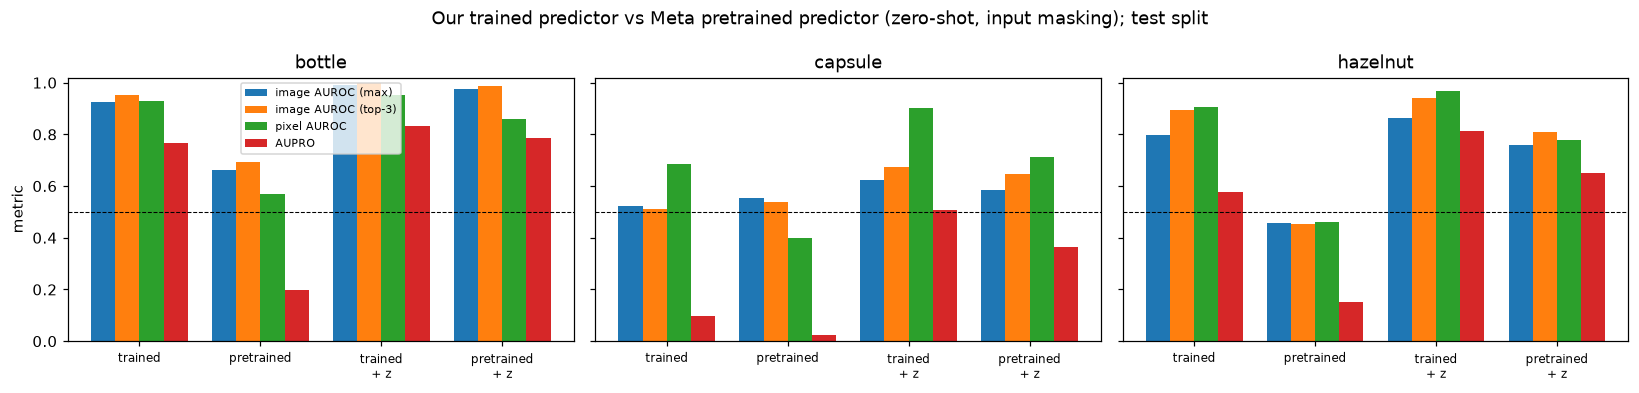

In [9]:
fig, axes = plt.subplots(1, len(CATEGORIES), figsize=(5 * len(CATEGORIES), 3.6), sharey=True)
width = 0.2
for ax, category in zip(np.atleast_1d(axes), CATEGORIES):
    view = metrics_df[metrics_df.category == category].set_index('row')
    for offset, (col, label) in enumerate((('image_auroc_max', 'image AUROC (max)'), (f'image_auroc_top{K}', f'image AUROC (top-{K})'), ('pixel_auroc', 'pixel AUROC'), ('aupro', 'AUPRO'))):
        ax.bar(np.arange(len(ROWS)) + (offset - 1.5) * width, [view.loc[r, col] for r in ROWS], width, label=label)
    ax.set_xticks(range(len(ROWS)))
    ax.set_xticklabels([r.replace(' + z', '\n+ z') for r in ROWS], fontsize=8)
    ax.set_title(category)
    ax.axhline(0.5, color='black', linewidth=0.7, linestyle='--')
    ax.set_ylim(0, 1.02)
np.atleast_1d(axes)[0].legend(fontsize=7)
np.atleast_1d(axes)[0].set_ylabel('metric')
fig.suptitle('Our trained predictor vs Meta pretrained predictor (zero-shot, input masking); test split')
fig.tight_layout()
plt.show()

## Save

In [10]:
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
(OUTPUT_ROOT / 'figures').mkdir(exist_ok=True)
if not OVERWRITE:
    existing = [OUTPUT_ROOT / n for n in OUTPUT_FILES if (OUTPUT_ROOT / n).exists()] + list((OUTPUT_ROOT / 'figures').glob('*.png'))
    if existing:
        raise FileExistsError('Refusing to overwrite: ' + ', '.join(map(str, existing)))
metrics_df.to_csv(OUTPUT_ROOT / 'zero_shot_metrics.csv', index=False)
boot_df.to_csv(OUTPUT_ROOT / 'bootstrap_deltas.csv', index=False)
nominal_df.to_csv(OUTPUT_ROOT / 'nominal_diagnostics.csv', index=False)
fig.savefig(OUTPUT_ROOT / 'figures' / 'zero_shot_comparison.png', dpi=150, bbox_inches='tight')
(OUTPUT_ROOT / 'zero_shot_summary.json').write_text(json.dumps({
    'what': 'Meta pretrained I-JEPA context encoder + predictor, input masking, zero-shot, 4x4 coarse windows, coarse-only',
    'trained': 'our baseline predictor, coarse pass only (reproduces results/calibration fixed row)',
    'trained_reproduces_saved_baseline': TRAINED_REPRODUCES,
    'settings_from_notebook_06': SELECTED,
    'position_zscore_statistics_from': 'all nominal validation images, per model',
    'no_training_no_fine_tuning': True, 'test_used_for_selection': False,
    'pretrained_model': {'loaded_with': 'torch.load(mmap=True, weights_only=True)', 'dtype': 'float32', 'encoder_sha256': ENCODER_SHA256,
                         'predictor': {'blocks': 16, 'width': 384, 'heads': 16}},
    'target_latents': 'cached target-encoder latents (not recomputed)',
    'bootstrap': {'n': N_BOOTSTRAP, 'seed': BOOTSTRAP_SEED},
    'headline_verdicts': boot_df[boot_df.comparison.str.startswith('HEADLINE')].set_index('category').verdict.to_dict(),
}, indent=2, sort_keys=True, default=str), encoding='utf-8')
print('saved to', OUTPUT_ROOT)

saved to C:\Users\aryan\OneDrive\Desktop\7 sem\I-JEPA-AD\results\improvements\pretrained_zero_shot


## What you can and cannot say

**You can say**

* Whether Meta's ImageNet-22k predictor, used as is with input masking, separates MVTec defects better or worse than our predictor trained on 188 to 352 nominal images, with paired-bootstrap intervals, under the same scoring settings.
* What it costs: the measured latency per image against the trained predictor's.
* That no weights were trained or changed, and that the per-position statistics came from nominal validation images only.

**You cannot say**

* That input masking is the reason for any difference: the pretrained model also differs in size (16 layers vs 4), training data (ImageNet-22k vs 200 images) and objective details. Separating the two would need a predictor trained on input-masked context latents (item 6 retraining).
* Anything about fine-tuning: this is zero-shot. A weak zero-shot result does not rule out a good fine-tuned one, and a good one does not show that fine-tuning is unnecessary.
* That an interval containing 0 shows an improvement or a harm.
* Anything about the dense or adaptive fine pass of the pretrained model: only the coarse pass was run.